<a href="https://colab.research.google.com/github/KanawadeSakshii/travel-reimbursement-agent/blob/main/SakshiKanawade.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Travel Reimbursement Approval Agent

A lightweight prototype that reviews travel reimbursement claims against the Appendix A policy and returns a structured decision: `APPROVE`, `PARTIAL_APPROVE`, `REJECT` or `MANUAL_REVIEW`.

**How it works**
1. **Claim intake**: claims are JSON objects (the five assignment claims, plus a UI to paste your own).
2. **LLM agent (Groq, tool calling)**: the model decides which tools to call (policy lookup, receipt check, expense-limit check, timeliness check, approval-threshold check), combines the evidence and submits a *proposed* decision.
3. **Deterministic validator**: Python recomputes every amount and rule. If the proposal disagrees, Python overrides it and records why. All money math is done in Python, never by the LLM.
4. **Safe fallback**: with no API key (or if Groq fails in `AUTO` mode) a deterministic local pipeline produces the proposal, so the notebook always runs end to end.
5. **Outputs**: agent trace, audit trail, tests, dashboard and the final nine-field JSON array.

## README

**Requirements:** Python 3.10+, `pandas`, `matplotlib`, `groq` (installed by the first code cell) and, optionally, `ipywidgets` for the interactive UI.

**Environment variable:** `GROQ_API_KEY` (a free key is available from console.groq.com).
- Google Colab: add it under *Secrets* (key icon) and enable notebook access.
- Local Jupyter: `export GROQ_API_KEY=...` before starting Jupyter.

**How to run:** open the notebook in Colab or Jupyter and choose *Run all*. No manual steps are needed.

**Modes** (`AGENT_MODE` in the configuration cell)
- `AUTO` (default): use Groq when a key is available, otherwise use the local fallback pipeline. If Groq fails for a claim, that claim falls back to the local pipeline and the reason is recorded.
- `GROQ`: strict mode. Any Groq failure raises an error, so nothing is hidden.
- `LOCAL`: never call an LLM.

**How to confirm the LLM really ran:** see the *Agent trace* section. It lists the orchestrator used for each claim (`groq` or `local_fallback`), the tools the model chose to call, the model's own reasoning, and whether Python had to override the proposal.

**Troubleshooting**
- `400 tool_use_failed`: the model formatted its final answer badly. The code recovers the answer automatically; if it still fails, re-run the cell.
- `429` rate limit: wait a minute and re-run.
- `orchestrator = local_fallback` in the trace: check `fallback_reason` (usually a missing key or an API error).

**Key design choice:** the LLM proposes and chooses tools, while Python is authoritative for every amount and policy outcome. See *Design Notes & Reasoning* below.

## Setup and configuration

**Groq setup:** add a Colab Secret (or environment variable) named `GROQ_API_KEY`. The next cell installs the Groq SDK. Set `AGENT_MODE = "GROQ"` to require Groq, or leave `AUTO` to fall back to the local pipeline if the key or API is unavailable.

In [1]:
%pip install -q -U groq

In [2]:
import os, json, re, copy
from datetime import datetime
from collections import defaultdict
import pandas as pd
import matplotlib.pyplot as plt

AGENT_MODE = "AUTO"  # AUTO = Groq if a key exists, otherwise the local pipeline; GROQ = strict (fail loudly); LOCAL = no LLM.
GROQ_MODEL = "openai/gpt-oss-120b"

POLICY = {
 "POL-CAT-01":"Eligible business expenses: economy airfare, lodging, meals, ground transport, and conference/registration fees.",
 "POL-CAT-02":"Ineligible personal expenses include alcohol/minibar, spa/gym/personal entertainment, in-room movies, personal shopping/gifts, traffic fines/penalties/late fees. Deduct ineligible expenses in full.",
 "POL-PD-01":"Meals: maximum $75 per day.",
 "POL-PD-02":"Lodging: maximum $200 per night.",
 "POL-PD-03":"Ground transport: maximum $50 per day.",
 "POL-AIR-01":"Economy airfare only. Business/first-class airfare is a policy exception and requires Manual Review if pre-approval cannot be verified.",
 "POL-RCT-01":"Itemized receipt required for any eligible single line item above $25. Airfare and lodging always require a receipt.",
 "POL-RCT-02":"Missing required receipts for otherwise eligible expenses require Manual Review.",
 "POL-APR-01":"Eligible total <= $500: auto-approval tier if all checks pass.",
 "POL-APR-02":"Eligible total > $500 and <= $2,000: manager approval tier if all checks pass.",
 "POL-APR-03":"Eligible total > $2,000: Manual Review/director approval required.",
 "POL-TIME-01":"Claims must be submitted within 30 days of the expense date; late claims require Manual Review."
}
CAPS = {"meals":75.0, "lodging":200.0, "ground_transport":50.0}
INELIGIBLE = {"alcohol","minibar","spa","gym","personal_entertainment","in_room_movies","personal_shopping","gifts","traffic_fines","penalties","late_fees","personal"}
ELIGIBLE = {"airfare","lodging","meals","ground_transport","conference_fees","registration"}
REQUIRED_AGENT_TOOLS = {"receipt_checker","expense_limit_checker"}  # the Groq agent must call these before submitting
OUTPUT_FIELDS = ["claim_id","decision","approved_amount","deducted_amount","missing_docs","policy_refs","confidence","explanation","tools_used"]
VALID_DECISIONS = {"APPROVE","PARTIAL_APPROVE","REJECT","MANUAL_REVIEW"}
print("Configuration loaded:", len(POLICY), "policy rules.")

Configuration loaded: 12 policy rules.


## Claim intake

The five claims are the assignment examples (Appendix B). Trip days and nights are derived from the trip dates, unless a line item states its own count (for example "3 nights"). A stated count that contradicts the trip dates is flagged as conflicting information and routed to Manual Review. Individual expense dates are not supplied, so the trip start date is the documented proxy for the 30-day timeliness rule.

In [3]:
claims = [
 {"claim_id":"CLM-001","employee":"A. Rivera","trip_start":"2026-06-10","trip_end":"2026-06-12","submitted_date":"2026-06-20","business_purpose":"Attend 2-day industry conference (business)","items":[
  {"category":"airfare","description":"Round-trip economy airfare","amount":420,"receipt_attached":True,"class":"economy"},
  {"category":"lodging","description":"Hotel, 2 nights @ $180","amount":360,"receipt_attached":True},
  {"category":"meals","description":"Meals, 3 trip days @ ~$60/day","amount":180,"receipt_attached":True},
  {"category":"conference_fees","description":"Conference registration","amount":150,"receipt_attached":True}]},
 {"claim_id":"CLM-002","employee":"B. Osei","trip_start":"2026-06-14","trip_end":"2026-06-15","submitted_date":"2026-06-25","business_purpose":"Weekend hotel stay","items":[
  {"category":"spa","description":"Hotel spa package","amount":300,"receipt_attached":True},
  {"category":"minibar","description":"In-room minibar","amount":80,"receipt_attached":True}]},
 {"claim_id":"CLM-003","employee":"C. Nakamura","trip_start":"2026-06-08","trip_end":"2026-06-10","submitted_date":"2026-06-22","business_purpose":"Client site visit (business)","items":[
  {"category":"airfare","description":"Round-trip economy airfare","amount":300,"receipt_attached":True,"class":"economy"},
  {"category":"lodging","description":"Hotel, 2 nights @ $250","amount":500,"receipt_attached":True},
  {"category":"meals","description":"Meals, 2 trip days @ $70/day","amount":140,"receipt_attached":True}]},
 {"claim_id":"CLM-004","employee":"D. Fischer","trip_start":"2026-06-16","trip_end":"2026-06-18","submitted_date":"2026-06-28","business_purpose":"International vendor negotiation (business)","items":[
  {"category":"airfare","description":"Business-class international airfare","amount":2400,"receipt_attached":True,"class":"business"},
  {"category":"lodging","description":"Hotel, 3 nights","amount":600,"receipt_attached":False}]},
 {"claim_id":"CLM-005","employee":"E. Haddad","trip_start":"2026-06-11","trip_end":"2026-06-11","submitted_date":"2026-06-24","business_purpose":"Client dinner / business development","items":[
  {"category":"meals","description":"Client dinner for 4 (business development)","amount":220,"receipt_attached":False}]}
]
def trip_nights(claim):
    return max((datetime.strptime(claim["trip_end"],"%Y-%m-%d").date()-datetime.strptime(claim["trip_start"],"%Y-%m-%d").date()).days, 0)
def trip_days(claim):
    return max(trip_nights(claim)+1, 1)
display(pd.DataFrame([{"claim_id":c["claim_id"],"employee":c["employee"],"claimed_total":sum(i["amount"] for i in c["items"]),
                       "trip_days":trip_days(c),"trip_nights":trip_nights(c)} for c in claims]))

,claim_id,employee,claimed_total,trip_days,trip_nights
0,CLM-001,A. Rivera,1110,3,2
1,CLM-002,B. Osei,380,2,1
2,CLM-003,C. Nakamura,940,3,2
3,CLM-004,D. Fischer,3000,3,2
4,CLM-005,E. Haddad,220,1,0


## Tools

These deterministic tools are what the agent calls. All arithmetic lives here.
- `policy_lookup` returns policy text for valid rule IDs. If the caller passes unknown IDs it says so and lists the valid ones, so an LLM can correct itself.
- `receipt_checker` skips ineligible items, because those are deducted in full under POL-CAT-02.
- `expense_limit_checker` applies per-category caps (meals, lodging, ground transport), flags non-economy airfare, unknown categories, and stated counts that conflict with the trip dates.
- `timeliness_checker` and `approval_threshold_checker` cover POL-TIME-01 and POL-APR-01/02/03.

In [4]:
def policy_lookup(rule_ids):
    """Return policy text for known rule IDs. Unknown IDs are reported so an LLM caller can self-correct."""
    ids=list(dict.fromkeys(rule_ids or []))
    found={rid: POLICY[rid] for rid in ids if rid in POLICY}
    unknown=[rid for rid in ids if rid not in POLICY]
    if unknown or not found:
        found["_unknown_rule_ids"]=unknown
        found["_valid_rule_ids"]=sorted(POLICY)
    return found

def relevant_policy_ids(claim):
    ids={"POL-CAT-01","POL-TIME-01"}
    cats={x["category"].lower() for x in claim["items"]}
    if cats & INELIGIBLE: ids.add("POL-CAT-02")
    if any((cat not in INELIGIBLE) and (cat in {"airfare","lodging"} or any(x["category"].lower()==cat and float(x["amount"])>25 for x in claim["items"])) for cat in cats): ids.add("POL-RCT-01")
    if "airfare" in cats: ids.add("POL-AIR-01")
    if "meals" in cats: ids.add("POL-PD-01")
    if "lodging" in cats: ids.add("POL-PD-02")
    if "ground_transport" in cats: ids.add("POL-PD-03")
    return sorted(ids)

NIGHTS_RE=r"(\d+)\s*nights?\b"
DAYS_RE=r"(\d+)\s*(?:trip\s+)?days?\b"
def stated_count(items, pattern):
    """Largest count stated in line-item descriptions (e.g. '3 nights', '2 trip days'); None if none is stated."""
    found=[int(n) for it in items for n in re.findall(pattern, str(it.get("description","")), flags=re.I)]
    return max(found) if found else None

def receipt_checker(claim):
    missing=[]; checked=[]
    for item in claim["items"]:
        cat=item["category"].lower()
        if cat in INELIGIBLE:
            continue
        required = cat in {"airfare","lodging"} or float(item["amount"]) > 25
        if required:
            checked.append(item["description"])
            if not item.get("receipt_attached",False):
                missing.append({"category":cat,"description":item["description"],"amount":round(float(item["amount"]),2)})
    refs=["POL-RCT-01"] if checked else []
    if missing: refs.append("POL-RCT-02")
    return {"missing_docs":missing,"checked_items":checked,"policy_refs":refs}

def expense_limit_checker(claim):
    # Aggregate by category across the claim before applying category caps.
    grouped=defaultdict(list)
    for item in claim["items"]:
        grouped[item["category"].lower()].append(item)
    rows=[]; refs=set(); review=[]
    days,nights=trip_days(claim),trip_nights(claim)
    for cat, items in grouped.items():
        total=round(sum(float(x["amount"]) for x in items),2)
        if cat in INELIGIBLE:
            refs.add("POL-CAT-02")
            rows.append({"category":cat,"claimed_amount":total,"eligible_amount":0.0,"deducted_amount":total,
                         "reason":"Ineligible category; deducted in full."})
            continue
        if cat not in ELIGIBLE:
            review.append(f"Unknown category '{cat}' requires review.")
            rows.append({"category":cat,"claimed_amount":total,"eligible_amount":0.0,"deducted_amount":0.0,
                         "reason":"Unknown category; unresolved pending review."})
            continue
        refs.add("POL-CAT-01")
        eligible=total; reason="Eligible; no monetary cap applies."
        if cat=="airfare":
            refs.add("POL-AIR-01")
            classes={str(x.get("class","")).lower() for x in items}
            if classes & {"business","first","first-class","first_class"}:
                review.append("Business/first-class airfare requires Manual Review; pre-approval is not available in the claim data.")
                reason="Non-economy airfare exception; unresolved pending review."
            elif classes != {"economy"}:
                review.append("Airfare class missing or unclear.")
                reason="Airfare class unclear; unresolved pending review."
        elif cat=="lodging":
            refs.add("POL-PD-02")
            stated=stated_count(items,NIGHTS_RE)
            cap_nights=stated if stated else nights
            if stated and stated>nights:
                review.append(f"Conflicting information: lodging states {stated} night(s) but the trip dates imply {nights}.")
            if cap_nights<=0:
                review.append("Cannot calculate lodging cap because the night count is unavailable.")
                reason="Night count unavailable."
            else:
                eligible=min(total,cap_nights*CAPS[cat])
                reason=f"Aggregate lodging cap: ${CAPS[cat]:.0f} x {cap_nights} night(s) ({'stated on claim' if stated else 'from trip dates'})."
        elif cat=="meals":
            refs.add("POL-PD-01")
            stated=stated_count(items,DAYS_RE)
            cap_days=stated if stated else days
            if stated and stated>days:
                review.append(f"Conflicting information: meals state {stated} day(s) but the trip dates imply {days}.")
            eligible=min(total,cap_days*CAPS[cat])
            reason=f"Aggregate meal cap: ${CAPS[cat]:.0f} x {cap_days} day(s) ({'stated on claim' if stated else 'from trip dates'})."
        elif cat=="ground_transport":
            refs.add("POL-PD-03")
            eligible=min(total,days*CAPS[cat]); reason=f"Aggregate transport cap: ${CAPS[cat]:.0f} x {days} trip day(s)."
        rows.append({"category":cat,"claimed_amount":total,"eligible_amount":round(eligible,2),
                     "deducted_amount":round(total-eligible,2),"reason":reason})
    return {"items":rows,"eligible_total":round(sum(x["eligible_amount"] for x in rows),2),
            "deducted_total":round(sum(x["deducted_amount"] for x in rows),2),
            "policy_refs":sorted(refs),"manual_reasons":review}

def timeliness_checker(claim):
    start=datetime.strptime(claim["trip_start"],"%Y-%m-%d").date()
    submitted=datetime.strptime(claim["submitted_date"],"%Y-%m-%d").date()
    elapsed=(submitted-start).days
    return {"days_elapsed_from_trip_start":elapsed,"late":elapsed>30,
            "policy_refs":["POL-TIME-01"] if elapsed>30 else [],
            "assumption":"Trip start date proxy; actual expense dates are not provided."}

def approval_threshold_checker(amount):
    amount=float(amount)
    if amount>2000: return {"tier":"MANUAL_REVIEW","manual_review":True,"policy_refs":["POL-APR-03"]}
    if amount>500: return {"tier":"MANAGER","manual_review":False,"policy_refs":["POL-APR-02"]}
    return {"tier":"AUTO","manual_review":False,"policy_refs":["POL-APR-01"]}

TOOL_REGISTRY={"policy_lookup":policy_lookup,"receipt_checker":receipt_checker,
               "expense_limit_checker":expense_limit_checker,"timeliness_checker":timeliness_checker,
               "approval_threshold_checker":approval_threshold_checker}

## Fallback pipeline (no API key)

A deterministic pipeline that runs the same tools in a fixed order and proposes a decision with plain rules. It is **not** the agentic path: it exists so the notebook is reproducible without credentials and as the fallback when Groq is unavailable.

In [5]:
def run_local_agent(claim):
    audit=[]
    def invoke(name, **kwargs):
        result=TOOL_REGISTRY[name](**kwargs)
        audit.append({"tool":name,"source":"local_agent","arguments":kwargs,"result":result})
        return result
    expenses=invoke("expense_limit_checker",claim=claim)
    threshold=invoke("approval_threshold_checker",amount=expenses["eligible_total"])
    selected_ids=relevant_policy_ids(claim)+threshold["policy_refs"]
    receipts=invoke("receipt_checker",claim=claim)
    timing=invoke("timeliness_checker",claim=claim)
    if receipts["missing_docs"]: selected_ids += ["POL-RCT-02"]
    policies=invoke("policy_lookup",rule_ids=selected_ids)
    reasons=list(expenses["manual_reasons"])
    if receipts["missing_docs"]: reasons.append("Required receipt(s) missing.")
    if timing["late"]: reasons.append("Claim submitted more than 30 days after trip start proxy.")
    if threshold["manual_review"]: reasons.append("Eligible total exceeds $2,000.")
    all_ineligible=all(x["category"] in INELIGIBLE for x in expenses["items"])
    if reasons: proposed="MANUAL_REVIEW"
    elif all_ineligible: proposed="REJECT"
    elif expenses["deducted_total"]>0: proposed="PARTIAL_APPROVE"
    else: proposed="APPROVE"
    return {"proposed_decision":proposed,"tool_evidence":{"policies":policies,"receipts":receipts,
            "expenses":expenses,"timeliness":timing,"threshold":threshold},
            "reasoning":reasons,"audit_log":audit}

## Groq tool-calling agent

With a Groq key, the model is given the five tools plus a `submit_decision` tool and chooses what to call:
- `policy_lookup` lists the valid rule IDs, so the model cannot invent them.
- The model must call `receipt_checker` and `expense_limit_checker` before `submit_decision` is accepted; otherwise it is told which tools are still missing.
- The final answer is delivered through `submit_decision`, so the model never has to produce free-form JSON. If Groq still rejects a malformed final answer (`tool_use_failed`), the answer is recovered from the error message.
- Every call is logged to the audit trail with `source = "llm_groq"`.

In [6]:
def get_groq_api_key():
    """Read Groq API key from Colab Secrets or environment variables."""
    key = os.environ.get("GROQ_API_KEY")
    if key and str(key).strip():
        return str(key).strip()
    try:
        from google.colab import userdata
        key = userdata.get("GROQ_API_KEY")
        if key and str(key).strip():
            return str(key).strip()
    except Exception:
        pass
    return None


import json, re

def _salvage_from_failed_generation(exc):
    """If Groq rejects the model's final JSON as a bogus tool call, recover the JSON from the error."""
    body = getattr(exc, "body", None) or {}
    err = body.get("error", body) if isinstance(body, dict) else {}
    if err.get("code") != "tool_use_failed":
        return None
    raw = err.get("failed_generation") or ""
    m = re.search(r"\{.*\}", raw, re.S)
    if not m:
        return None
    try:
        obj = json.loads(m.group(0))
    except Exception:
        return None
    obj = obj.get("arguments", obj) if isinstance(obj, dict) else None
    if isinstance(obj, str):
        try: obj = json.loads(obj)
        except Exception: return None
    return obj if isinstance(obj, dict) and "proposed_decision" in obj else None

def run_groq_agent(claim):
    from groq import Groq
    key = get_groq_api_key()
    if not key:
        raise RuntimeError("GROQ_API_KEY not found. Add it in Colab Secrets or environment variables.")
    client = Groq(api_key=key)

    def fn(name, desc, props, req):
        return {"type": "function", "function": {"name": name, "description": desc,
                "parameters": {"type": "object", "properties": props, "required": req}}}
    valid_ids = sorted(POLICY)
    tools = [
        fn("policy_lookup", "Retrieve policy text. Use ONLY these rule IDs: " + ", ".join(valid_ids) + ".",
           {"rule_ids": {"type": "array", "items": {"type": "string", "enum": valid_ids}}}, ["rule_ids"]),
        fn("receipt_checker", "Check required receipts for claim items.", {"claim_id": {"type": "string"}}, ["claim_id"]),
        fn("expense_limit_checker", "Calculate eligible and deducted amounts under category caps.", {"claim_id": {"type": "string"}}, ["claim_id"]),
        fn("timeliness_checker", "Check claim submission timeliness.", {"claim_id": {"type": "string"}}, ["claim_id"]),
        fn("approval_threshold_checker", "Determine approval tier for an eligible amount.", {"amount": {"type": "number"}}, ["amount"]),
        # Final answer is delivered through a tool call, so the model never has to emit free-form JSON.
        fn("submit_decision", "Call this LAST, exactly once, with your final proposal after using the other tools.",
           {"proposed_decision": {"type": "string", "enum": ["APPROVE", "PARTIAL_APPROVE", "REJECT", "MANUAL_REVIEW"]},
            "reasoning": {"type": "array", "items": {"type": "string"}},
            "missing_information": {"type": "array", "items": {"type": "string"}}},
           ["proposed_decision", "reasoning"]),
    ]
    system_prompt = (
        "You are a travel reimbursement review agent. Decide which tools are relevant and call them when needed. "
        "You MUST call receipt_checker and expense_limit_checker before submitting. Use policy_lookup only with these "
        "rule IDs: " + ", ".join(valid_ids) + ". Do not invent policy rules, receipts, dates or approvals. "
        "Prefer MANUAL_REVIEW when information is missing, conflicting or an exception applies. "
        "When you have enough evidence, finish by calling submit_decision exactly once. "
        "Do not write the final answer as plain text or as JSON in a message. Python will independently validate "
        "and may override your proposal.")
    messages = [{"role": "system", "content": system_prompt},
                {"role": "user", "content": "Evaluate this claim:\n" + json.dumps(claim)}]
    audit = []
    tool_functions = {
        "policy_lookup": lambda a: policy_lookup(a.get("rule_ids", [])),
        "receipt_checker": lambda a: receipt_checker(claim),
        "expense_limit_checker": lambda a: expense_limit_checker(claim),
        "timeliness_checker": lambda a: timeliness_checker(claim),
        "approval_threshold_checker": lambda a: approval_threshold_checker(a["amount"]),
    }

    def missing_required():
        called = {a["tool"] for a in audit if a.get("source") == "llm_groq"}
        return sorted(REQUIRED_AGENT_TOOLS - called)

    proposal = None
    for _ in range(10):
        try:
            response = client.chat.completions.create(model=GROQ_MODEL, messages=messages,
                                                      tools=tools, tool_choice="auto", temperature=0)
        except Exception as exc:
            recovered = _salvage_from_failed_generation(exc)   # recover the model's own final JSON
            if recovered is None:
                raise
            if missing_required():
                messages.append({"role": "user", "content": "Before submitting, call these tools: " + ", ".join(missing_required()) + "."})
                continue
            proposal = recovered
            audit.append({"tool": "submit_decision", "source": "llm_groq", "arguments": proposal,
                          "result": {"note": "recovered from tool_use_failed"}})
            break
        message = response.choices[0].message
        messages.append(message.model_dump(exclude_none=True))
        if not message.tool_calls:                               # plain-text fallback
            m = re.search(r"\{.*\}", message.content or "", re.S)
            if m and not missing_required():
                proposal = json.loads(m.group(0)); break
            need = missing_required()
            messages.append({"role": "user", "content": ("Call these tools first: " + ", ".join(need) + ". Then " if need else "")
                             + "finish by calling submit_decision."})
            continue
        for tc in message.tool_calls:
            name = tc.function.name
            try:
                args = json.loads(tc.function.arguments or "{}")
            except Exception:
                args = {}
            if name == "submit_decision":
                need = missing_required()
                if need:                                          # refuse to accept a decision made without tool evidence
                    audit.append({"tool": name, "source": "llm_groq", "arguments": args,
                                  "result": {"accepted": False, "missing_tools": need}})
                    messages.append({"role": "tool", "tool_call_id": tc.id, "name": name,
                                     "content": json.dumps({"accepted": False, "error": "Call these tools first: " + ", ".join(need)})})
                    continue
                proposal = args
                audit.append({"tool": name, "source": "llm_groq", "arguments": args, "result": {"accepted": True}})
                messages.append({"role": "tool", "tool_call_id": tc.id, "name": name, "content": '{"accepted": true}'})
                continue
            try:
                result = tool_functions[name](args) if name in tool_functions else {"error": "Tool not permitted"}
            except Exception as e:
                result = {"error": f"{type(e).__name__}: {e}"}
            audit.append({"tool": name, "source": "llm_groq", "arguments": args, "result": result})
            messages.append({"role": "tool", "tool_call_id": tc.id, "name": name, "content": json.dumps(result, default=str)})
        if proposal is not None:
            break
    if proposal is None:
        raise RuntimeError("Groq did not submit a decision with the required tool evidence within the turn limit.")
    return {"proposed_decision": proposal.get("proposed_decision"), "reasoning": proposal.get("reasoning", []),
            "missing_information": proposal.get("missing_information", []), "audit_log": audit,
            "raw_response": json.dumps(proposal)}

## Policy validator, override and audit trail

Python independently recomputes the policy outcome from the claim. If the agent's proposal disagrees, the validator overrides it, and the final explanation states what the agent proposed and why Python changed it. For unresolved Manual Review claims both `approved_amount` and `deducted_amount` are zero, because calculated potential deductions are not final until a human decides. `tools_used` lists only the tools the **agent** called; the validator's own re-computation is kept separately in the audit trail.

In [7]:
def reason_based_confidence(decision, reasons, missing_docs, unknowns):
    score={"APPROVE":0.97,"PARTIAL_APPROVE":0.94,"REJECT":0.97,"MANUAL_REVIEW":0.82}[decision]
    score-=min(0.20,0.04*len(reasons))
    score-=min(0.12,0.04*len(missing_docs))
    score-=min(0.12,0.06*len(unknowns))
    return round(max(0.50,min(0.99,score)),2)

def validate_and_finalize(claim, agent_result):
    ev=agent_result["tool_evidence"] if "tool_evidence" in agent_result else None
    # Always recompute authoritative evidence in Python, independent of LLM output.
    policy=policy_lookup(relevant_policy_ids(claim))
    receipts=receipt_checker(claim)
    expenses=expense_limit_checker(claim)
    timing=timeliness_checker(claim)
    threshold=approval_threshold_checker(expenses["eligible_total"])
    reasons=list(expenses["manual_reasons"])
    if receipts["missing_docs"]: reasons.append("Required receipt(s) missing; obtain documentation.")
    if timing["late"]: reasons.append("Submission is more than 30 days after trip-start proxy.")
    if threshold["manual_review"]: reasons.append("Eligible total exceeds $2,000; director/manual approval required.")
    unknowns=[x["category"] for x in expenses["items"] if x["category"] not in ELIGIBLE and x["category"] not in INELIGIBLE]
    all_ineligible=bool(expenses["items"]) and all(x["category"] in INELIGIBLE for x in expenses["items"])
    if reasons: authoritative="MANUAL_REVIEW"
    elif all_ineligible: authoritative="REJECT"
    elif expenses["deducted_total"]>0: authoritative="PARTIAL_APPROVE"
    else: authoritative="APPROVE"

    proposed=agent_result.get("proposed_decision")
    valid_proposal=proposed in VALID_DECISIONS
    overridden=(not valid_proposal) or proposed!=authoritative
    # Conservative fail-safe: authoritative Python policy result always wins.
    decision=authoritative
    if decision=="MANUAL_REVIEW":
        approved=0.0
        deducted=0.0  # No finalized financial disposition while review is pending.
    elif decision=="REJECT":
        approved=0.0
        deducted=round(sum(float(i["amount"]) for i in claim["items"]),2)
    else:
        approved=expenses["eligible_total"]
        deducted=expenses["deducted_total"]

    # Cite only the rules that drove the outcome (no blanket citations).
    if all_ineligible:
        refs={"POL-CAT-02"}
    else:
        refs=set(expenses["policy_refs"])|set(receipts["policy_refs"])|set(timing["policy_refs"])
        if decision in ("APPROVE","PARTIAL_APPROVE") or threshold["manual_review"]:
            refs.update(threshold["policy_refs"])
    if receipts["missing_docs"]: refs.add("POL-RCT-02")
    if timing["late"]: refs.add("POL-TIME-01")
    refs=sorted(refs)
    orch=agent_result.get("orchestrator","local")
    why="; ".join(str(x) for x in (agent_result.get("reasoning") or [])[:2])
    if overridden:
        agent_note=(f"Agent ({orch}) proposed {proposed}"+(f" ({why})" if why else "")
                    +f"; deterministic policy validation changed it to {decision}. ")
    else:
        agent_note=f"Agent ({orch}) proposal ({proposed}) matched policy validation. "
    explanation=("Python policy validator selected "+decision+". "+agent_note
                 + (" ".join(reasons) if reasons else "All required checks passed.")
                 + " Timeliness uses trip start as a proxy because individual expense dates are unavailable.")
    if decision=="MANUAL_REVIEW":
        explanation+=" No amount is finalized pending human review."
    audit=copy.deepcopy(agent_result.get("audit_log",[]))
    # These five Python calls above are actual validator executions; record their inputs/results explicitly.
    validator_results={"policy_lookup":policy,"receipt_checker":receipts,"expense_limit_checker":expenses,
                       "timeliness_checker":timing,"approval_threshold_checker":threshold}
    validator_args={"policy_lookup":{"rule_ids":relevant_policy_ids(claim)+threshold["policy_refs"]},
                    "receipt_checker":{"claim_id":claim["claim_id"]},
                    "expense_limit_checker":{"claim_id":claim["claim_id"]},
                    "timeliness_checker":{"claim_id":claim["claim_id"]},
                    "approval_threshold_checker":{"amount":expenses["eligible_total"]}}
    for name,value in validator_results.items():
        audit.append({"tool":name,"source":"python_validator","arguments":validator_args[name],"result":value})
    actual_tools = list(dict.fromkeys(
    e["tool"] for e in audit
    if e.get("source") in ("llm_groq", "local_agent") and e["tool"] != "submit_decision"))
    confidence=reason_based_confidence(decision,reasons,receipts["missing_docs"],unknowns)
    result={"claim_id":claim["claim_id"],"decision":decision,"approved_amount":round(approved,2),
            "deducted_amount":round(deducted,2),"missing_docs":receipts["missing_docs"],
            "policy_refs":refs,"confidence":confidence,"explanation":explanation,"tools_used":actual_tools}
    audit.append({"tool":"python_policy_validator","source":"python_validator","arguments":{"claim_id":claim["claim_id"],"agent_proposal":proposed},
                  "result":{"authoritative_decision":decision,"overridden":overridden,"orchestrator":orch,
                            "llm_reasoning":agent_result.get("reasoning"),"eligible_calculation":expenses,
                            "receipt_check":receipts,"timeliness":timing,"threshold":threshold}})
    return result, audit, {"proposed_decision": proposed, "authoritative_decision": decision,
        "overridden": overridden,
        "orchestrator": agent_result.get("orchestrator", "unknown"),
        "fallback_reason": agent_result.get("groq_fallback_reason")}

def process_claim(claim, mode=AGENT_MODE):
    use_groq = (mode == "GROQ") or (mode == "AUTO" and bool(get_groq_api_key()))
    if use_groq:
        try:
            agent = run_groq_agent(claim)
            agent["orchestrator"] = "groq"
        except Exception as exc:
            if mode == "GROQ":
                raise
            agent = run_local_agent(claim)
            agent["orchestrator"] = "local_fallback"
            agent["groq_fallback_reason"] = f"{type(exc).__name__}: {str(exc)[:500]}"
            agent.setdefault("audit_log", []).append({
                "tool": "groq_fallback", "source": "system",
                "arguments": {"model": GROQ_MODEL},
                "result": {"status": "fallback_to_local_agent",
                           "reason": agent["groq_fallback_reason"]}
            })
    else:
        agent = run_local_agent(claim)
        agent["orchestrator"] = "local"
    return validate_and_finalize(claim, agent)

processed=[process_claim(c) for c in claims]
results=[x[0] for x in processed]
audit_trails={c["claim_id"]:x[1] for c,x in zip(claims,processed)}
decision_checks={c["claim_id"]:x[2] for c,x in zip(claims,processed)}
display(pd.DataFrame([{"claim_id":r["claim_id"],"agent_proposal":decision_checks[r["claim_id"]]["proposed_decision"],
                       "final_decision":r["decision"],"overridden":decision_checks[r["claim_id"]]["overridden"],
                       "approved":r["approved_amount"],"deducted":r["deducted_amount"],"orchestrator":decision_checks[r["claim_id"]]["orchestrator"],
                       "tools_called":", ".join(r["tools_used"])}
                      for r in results]))

,claim_id,agent_proposal,final_decision,overridden,approved,deducted,orchestrator,tools_called
0,CLM-001,APPROVE,APPROVE,False,1110.0,0.0,groq,"receipt_checker, expense_limit_checker, policy..."
1,CLM-002,REJECT,REJECT,False,0.0,380.0,groq,"policy_lookup, receipt_checker, expense_limit_..."
2,CLM-003,APPROVE,PARTIAL_APPROVE,True,840.0,100.0,groq,"receipt_checker, expense_limit_checker, policy..."
3,CLM-004,MANUAL_REVIEW,MANUAL_REVIEW,False,0.0,0.0,local_fallback,"expense_limit_checker, approval_threshold_chec..."
4,CLM-005,MANUAL_REVIEW,MANUAL_REVIEW,False,0.0,0.0,groq,"policy_lookup, expense_limit_checker, receipt_..."


## Agent trace

Shows, per claim, which orchestrator ran, which tools the agent chose to call, what it proposed, and whether Python overrode it. This is the evidence that the LLM tool-calling workflow actually executed.

In [8]:
print("Mode:", AGENT_MODE, "| model:", GROQ_MODEL)
trace=[]
for cid,check in decision_checks.items():
    trail=audit_trails[cid]
    agent_tools=list(dict.fromkeys(e["tool"] for e in trail
                     if e.get("source") in ("llm_groq","local_agent") and e["tool"]!="submit_decision"))
    trace.append({"claim_id":cid,"orchestrator":check["orchestrator"],"agent_tools":", ".join(agent_tools),
                  "agent_proposal":check["proposed_decision"],"final_decision":check["authoritative_decision"],
                  "overridden":check["overridden"],"fallback_reason":check["fallback_reason"] or ""})
display(pd.DataFrame(trace))
if AGENT_MODE=="GROQ":
    assert all(v["orchestrator"]=="groq" for v in decision_checks.values()), "Groq did not run for every claim"
if any(v["orchestrator"]=="local_fallback" for v in decision_checks.values()):
    print("WARNING: some claims fell back to the local pipeline; see fallback_reason above.")
elif all(v["orchestrator"]=="local" for v in decision_checks.values()):
    print("NOTE: no Groq key was found, so the local fallback pipeline was used (no LLM).")
print("\nAgent reasoning submitted via submit_decision:")
for cid,trail in audit_trails.items():
    sub=[e for e in trail if e["tool"]=="submit_decision" and e.get("source")=="llm_groq"]
    if sub:
        print(f"- {cid}: {sub[-1]['arguments'].get('proposed_decision')} | {sub[-1]['arguments'].get('reasoning')}")

Mode: AUTO | model: openai/gpt-oss-120b


,claim_id,orchestrator,agent_tools,agent_proposal,final_decision,overridden,fallback_reason
0,CLM-001,groq,"receipt_checker, expense_limit_checker, policy...",APPROVE,APPROVE,False,
1,CLM-002,groq,"policy_lookup, receipt_checker, expense_limit_...",REJECT,REJECT,False,
2,CLM-003,groq,"receipt_checker, expense_limit_checker, policy...",APPROVE,PARTIAL_APPROVE,True,
3,CLM-004,local_fallback,"expense_limit_checker, approval_threshold_chec...",MANUAL_REVIEW,MANUAL_REVIEW,False,RateLimitError: Error code: 429 - {'error': {'...
4,CLM-005,groq,"policy_lookup, expense_limit_checker, receipt_...",MANUAL_REVIEW,MANUAL_REVIEW,False,



Agent reasoning submitted via submit_decision:
- CLM-001: APPROVE | ['All required receipts are attached and verified (receipt_checker).', 'All expense items are within policy caps and eligible amounts (expense_limit_checker).', 'Airfare is economy class, complying with POL-AIR-01.', 'Lodging and meals are within per diem caps per POL-PD-01 and POL-PD-02.', 'Claim submitted within 30 days of trip end, satisfying POL-TIME-01.']
- CLM-002: REJECT | ['Policy POL-CAT-02 defines spa and minibar expenses as ineligible personal expenses and must be deducted in full.', 'Expense limit check shows both items have eligible_amount 0 and are fully deducted.', 'No eligible expenses remain for reimbursement; claim total eligible amount is $0.00.']
- CLM-003: APPROVE | ['All required receipts are attached (receipt_checker).', 'Expense limits applied: airfare fully eligible, lodging capped at $200 per night resulting in $100 deduction, meals within per diem cap (expense_limit_checker).', 'Claim submit

## Tests

Covers the five assignment claims plus: late submission, first-class airfare, unknown category, mixed eligible and ineligible items, an ineligible item with no receipt, conflicting night counts, a wrong LLM proposal being overridden, and an invalid proposal.

In [9]:
def make_test_claim(claim_id, items, submitted="2026-06-20", start="2026-06-10", end="2026-06-12"):
    return {"claim_id":claim_id,"employee":"Test","trip_start":start,"trip_end":end,"submitted_date":submitted,
            "business_purpose":"Test business purpose","items":items}

edge_cases=[
 make_test_claim("EDGE-LATE",[{"category":"meals","description":"Meal","amount":50,"receipt_attached":True,"days":1}],submitted="2026-07-20"),
 make_test_claim("EDGE-FIRST",[{"category":"airfare","description":"First class fare","amount":500,"receipt_attached":True,"class":"first"}]),
 make_test_claim("EDGE-UNKNOWN",[{"category":"misc_unknown","description":"Unknown item","amount":40,"receipt_attached":True}]),
 make_test_claim("EDGE-MIXED",[{"category":"meals","description":"Business meal","amount":50,"receipt_attached":True},
                              {"category":"minibar","description":"Minibar","amount":30,"receipt_attached":False}]),
 make_test_claim("EDGE-SPA-NORECEIPT",[{"category":"spa","description":"Spa","amount":300,"receipt_attached":False}])
]
edge_cases.append(make_test_claim("EDGE-NIGHTS",[{"category":"lodging","description":"Hotel, 3 nights","amount":600,"receipt_attached":True}],start="2026-06-10",end="2026-06-11"))
edge_results=[]
for c in edge_cases:
    local=run_local_agent(c)
    final,audit,check=validate_and_finalize(c,local)
    edge_results.append(final)

assert [r["decision"] for r in results]==["APPROVE","REJECT","PARTIAL_APPROVE","MANUAL_REVIEW","MANUAL_REVIEW"]
assert results[2]["approved_amount"]==840.0 and results[2]["deducted_amount"]==100.0
assert results[3]["approved_amount"]==0.0 and results[3]["deducted_amount"]==0.0
assert results[4]["approved_amount"]==0.0 and results[4]["deducted_amount"]==0.0
assert edge_results[0]["decision"]=="MANUAL_REVIEW"  # late
assert edge_results[1]["decision"]=="MANUAL_REVIEW"  # first class
assert edge_results[2]["decision"]=="MANUAL_REVIEW"  # unknown category
assert edge_results[3]["decision"]=="PARTIAL_APPROVE" # mixed eligible and ineligible
assert edge_results[4]["decision"]=="REJECT" # ineligible item does not require receipt
assert edge_results[5]["decision"]=="MANUAL_REVIEW"  # lodging nights conflict with trip dates
assert expense_limit_checker(claims[3])["eligible_total"]==3000.0  # CLM-004 uses the stated 3 nights
assert results[1]["policy_refs"]==["POL-CAT-02"]  # a rejection cites only the ineligible-category rule
assert all("POL-TIME-01" not in r["policy_refs"] for r in results)  # no claim is late
assert all(len(r["tools_used"])>=2 for r in results+edge_results)  # every claim shows real tool usage
# A wrong LLM proposal must be overridden by the validator
wrong=validate_and_finalize(claims[3],{"proposed_decision":"APPROVE","reasoning":["pretend the LLM approved"],"audit_log":[],"orchestrator":"test"})
assert wrong[0]["decision"]=="MANUAL_REVIEW" and wrong[2]["overridden"] and "changed it" in wrong[0]["explanation"]
# An invalid proposal is also overridden
invalid=validate_and_finalize(claims[0],{"proposed_decision":"MAYBE","audit_log":[]})
assert invalid[0]["decision"]=="APPROVE" and invalid[2]["overridden"]
print("Assignment claims and all edge-case tests passed.")
display(pd.DataFrame([{"claim_id":r["claim_id"],"decision":r["decision"],"approved":r["approved_amount"],"deducted":r["deducted_amount"],"missing_docs":len(r["missing_docs"])} for r in edge_results]))

Assignment claims and all edge-case tests passed.


,claim_id,decision,approved,deducted,missing_docs
0,EDGE-LATE,MANUAL_REVIEW,0.0,0.0,0
1,EDGE-FIRST,MANUAL_REVIEW,0.0,0.0,0
2,EDGE-UNKNOWN,MANUAL_REVIEW,0.0,0.0,0
3,EDGE-MIXED,PARTIAL_APPROVE,50.0,30.0,0
4,EDGE-SPA-NORECEIPT,REJECT,0.0,300.0,0
5,EDGE-NIGHTS,MANUAL_REVIEW,0.0,0.0,0


## Interactive UI

Pick a sample claim or paste a claim JSON object and press **Evaluate claim**. It uses the same orchestrator (`AGENT_MODE`) and validator as the main run. If `ipywidgets` is unavailable, call `evaluate_custom_claim(claim_json)` from the next cell.

In [10]:
try:
    import ipywidgets as widgets
    from IPython.display import display, clear_output
    claim_options=[(f'{c["claim_id"]} — {c["employee"]}',c["claim_id"]) for c in claims]
    claim_dropdown=widgets.Dropdown(options=claim_options,description="Sample claim:")
    custom_json=widgets.Textarea(value="",placeholder="Optional: paste a complete claim JSON object to evaluate instead.",description="Custom JSON:",layout=widgets.Layout(width="95%",height="130px"))
    run_button=widgets.Button(description="Evaluate claim",button_style="primary")
    ui_output=widgets.Output()
    def on_run_clicked(_):
        with ui_output:
            clear_output()
            try:
                if custom_json.value.strip():
                    selected=json.loads(custom_json.value)
                else:
                    selected=copy.deepcopy(next(c for c in claims if c["claim_id"]==claim_dropdown.value))
                result,audit,check=process_claim(selected)
                print("Orchestrator:",check["orchestrator"])
                print("Agent proposal:",check["proposed_decision"])
                print("Validated decision:",check["authoritative_decision"])
                print("Overridden:",check["overridden"])
                print(json.dumps(result,indent=2))
                print("\nAudit trail:")
                print(json.dumps(audit,indent=2))
            except Exception as e:
                print("Input/evaluation error:",e)
    run_button.on_click(on_run_clicked)
    display(widgets.VBox([claim_dropdown,custom_json,run_button,ui_output]))
except Exception as e:
    print("ipywidgets UI unavailable in this environment:",e)
    print("Use evaluate_custom_claim(claim_json) in the next cell.")

In [11]:
def evaluate_custom_claim(claim_json):
    claim=json.loads(claim_json) if isinstance(claim_json,str) else claim_json
    result,audit,check=process_claim(claim)
    return {"result":result,"audit_trail":audit,"validation":check}

# Example:
# evaluate_custom_claim('{"claim_id":"CUSTOM-01","employee":"Test","trip_start":"2026-06-10","trip_end":"2026-06-10","submitted_date":"2026-06-15","business_purpose":"Client meeting","items":[{"category":"meals","description":"Lunch","amount":40,"receipt_attached":true}]}')

## Dashboard

,claim_id,decision,approved_amount,deducted_amount,missing_docs,confidence,orchestrator
0,CLM-001,APPROVE,1110.0,0.0,0,0.97,groq
1,CLM-002,REJECT,0.0,380.0,0,0.97,groq
2,CLM-003,PARTIAL_APPROVE,840.0,100.0,0,0.94,groq
3,CLM-004,MANUAL_REVIEW,0.0,0.0,1,0.62,local_fallback
4,CLM-005,MANUAL_REVIEW,0.0,0.0,1,0.74,groq


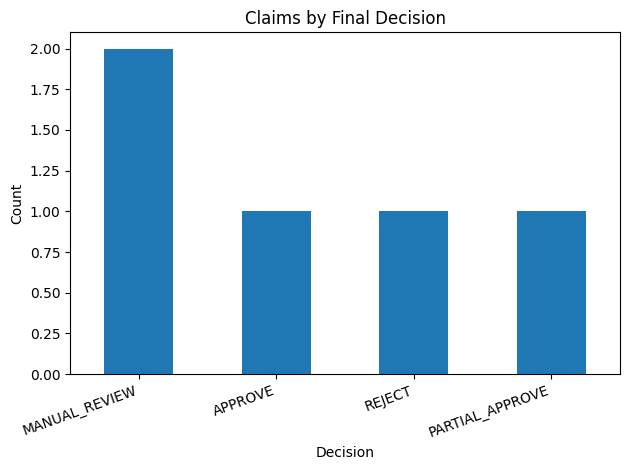

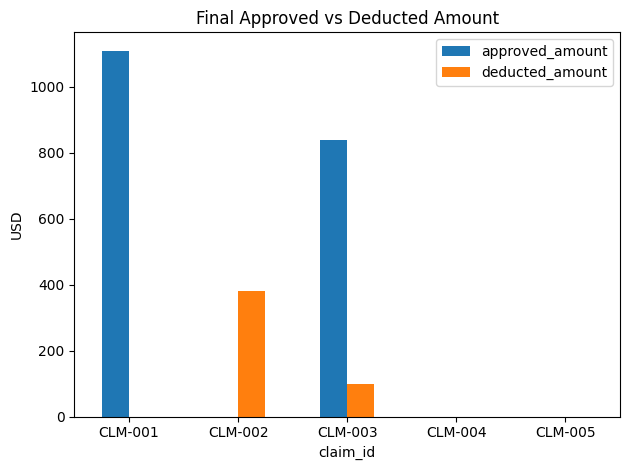

Total claimed USD: 5650
Final approved USD: 1950.0
Final deducted USD: 480.0
Claims routed to Manual Review: 2 of 5

Sample decisions and explanations:


,claim_id,decision,explanation
0,CLM-001,APPROVE,Python policy validator selected APPROVE. Agent (groq) proposal (APPROVE) matched policy validation. All required checks passed. Timeliness uses trip start as a proxy because individual expense dates are unavailable.
1,CLM-002,REJECT,Python policy validator selected REJECT. Agent (groq) proposal (REJECT) matched policy validation. All required checks passed. Timeliness uses trip start as a proxy because individual expense dates are unavailable.
2,CLM-003,PARTIAL_APPROVE,"Python policy validator selected PARTIAL_APPROVE. Agent (groq) proposed APPROVE (All required receipts are attached (receipt_checker).; Expense limits applied: airfare fully eligible, lodging capped at $200 per night resulting in $100 deduction, meals within per diem cap (expense_limit_checker).); deterministic policy validation changed it to PARTIAL_APPROVE. All required checks passed. Timeliness uses trip start as a proxy because individual expense dates are unavailable."
3,CLM-004,MANUAL_REVIEW,"Python policy validator selected MANUAL_REVIEW. Agent (local_fallback) proposal (MANUAL_REVIEW) matched policy validation. Business/first-class airfare requires Manual Review; pre-approval is not available in the claim data. Conflicting information: lodging states 3 night(s) but the trip dates imply 2. Required receipt(s) missing; obtain documentation. Eligible total exceeds $2,000; director/manual approval required. Timeliness uses trip start as a proxy because individual expense dates are unavailable. No amount is finalized pending human review."
4,CLM-005,MANUAL_REVIEW,Python policy validator selected MANUAL_REVIEW. Agent (groq) proposal (MANUAL_REVIEW) matched policy validation. Required receipt(s) missing; obtain documentation. Timeliness uses trip start as a proxy because individual expense dates are unavailable. No amount is finalized pending human review.



Audit trail (every tool call, agent and validator):


,claim_id,source,tool,arguments
0,CLM-001,llm_groq,receipt_checker,"{""claim_id"": ""CLM-001""}"
1,CLM-001,llm_groq,expense_limit_checker,"{""claim_id"": ""CLM-001""}"
2,CLM-001,llm_groq,policy_lookup,"{""rule_ids"": [""POL-TIME-01""]}"
3,CLM-001,llm_groq,policy_lookup,"{""rule_ids"": [""POL-AIR-01""]}"
4,CLM-001,llm_groq,submit_decision,"{""missing_information"": [], ""proposed_decision..."
5,CLM-001,python_validator,policy_lookup,"{""rule_ids"": [""POL-AIR-01"", ""POL-CAT-01"", ""POL..."
6,CLM-001,python_validator,receipt_checker,"{""claim_id"": ""CLM-001""}"
7,CLM-001,python_validator,expense_limit_checker,"{""claim_id"": ""CLM-001""}"
8,CLM-001,python_validator,timeliness_checker,"{""claim_id"": ""CLM-001""}"
9,CLM-001,python_validator,approval_threshold_checker,"{""amount"": 1110.0}"


In [12]:
df=pd.DataFrame([{"claim_id":r["claim_id"],"decision":r["decision"],"approved_amount":r["approved_amount"],
                  "deducted_amount":r["deducted_amount"],"missing_docs":len(r["missing_docs"]),
                  "confidence":r["confidence"],"orchestrator":decision_checks[r["claim_id"]]["orchestrator"]} for r in results])
display(df)
df["decision"].value_counts().plot(kind="bar",title="Claims by Final Decision",xlabel="Decision",ylabel="Count")
plt.xticks(rotation=20,ha="right"); plt.tight_layout(); plt.show()
df.set_index("claim_id")[["approved_amount","deducted_amount"]].plot(kind="bar",title="Final Approved vs Deducted Amount",ylabel="USD")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()
print("Total claimed USD:",round(sum(sum(i["amount"] for i in c["items"]) for c in claims),2))
print("Final approved USD:",round(df["approved_amount"].sum(),2))
print("Final deducted USD:",round(df["deducted_amount"].sum(),2))
print("Claims routed to Manual Review:",int((df["decision"]=="MANUAL_REVIEW").sum()),"of",len(df))

print("\nSample decisions and explanations:")
with pd.option_context("display.max_colwidth",None):
    display(pd.DataFrame([{"claim_id":r["claim_id"],"decision":r["decision"],"explanation":r["explanation"]} for r in results]))

print("\nAudit trail (every tool call, agent and validator):")
rows=[]
for cid,trail in audit_trails.items():
    for e in trail:
        rows.append({"claim_id":cid,"source":e.get("source","-"),"tool":e["tool"],
                     "arguments":json.dumps(e["arguments"],default=str)[:80]})
with pd.option_context("display.max_rows",None):
    display(pd.DataFrame(rows))

## Design Notes & Reasoning

**Architecture.** An LLM agent proposes; deterministic Python decides. The agent chooses which tools to call and summarises the evidence, but every amount, cap and threshold is computed by tools, and a validator recomputes the policy outcome independently. The LLM never does arithmetic. This keeps the GenAI part useful (tool selection, combining evidence, readable reasoning) while keeping the money part exact and auditable.

**Grounding.** Policy text comes only from `policy_lookup`. The tool exposes the valid rule IDs, and reports unknown IDs back to the model. During testing the model invented rule names and received empty results, which is why this was added.

**Why Manual Review.** A claim is routed to Manual Review, never forced into a decision, when any of these hold:
- a required receipt is missing (POL-RCT-02);
- airfare is business or first class, because a pre-approval may exist (POL-AIR-01);
- the eligible total is above $2,000 (POL-APR-03);
- the submission is more than 30 days after the expense date (POL-TIME-01);
- the category is unknown, or the claim contradicts itself, for example a lodging line stating more nights than the trip dates allow.

In these cases `approved_amount` and `deducted_amount` are both `0`, because no financial outcome is final until a human reviews the claim.

**Override behaviour.** LLM proposals vary between runs. In one run the model proposed Manual Review for a fully compliant claim. The validator corrected it and the explanation records the disagreement. This is the main reliability trade-off: the LLM adds flexibility but is never trusted with the final decision.

**Trade-offs.**
- A rules-engine-plus-LLM split is more code than a single prompt, but it removes arithmetic and policy errors from the model.
- Requiring `receipt_checker` and `expense_limit_checker` before a decision costs one or two extra model turns, but guarantees every claim has tool evidence.
- A deterministic local fallback is kept so the notebook runs without a key. It is deliberately labelled as not agentic.
- Confidence is a reason-based heuristic (it drops with each manual-review reason, missing document or unknown category). It is not a calibrated probability.

**Assumptions and simplifications.**
- Expense-level dates are not provided, so the trip start date is used for the 30-day check.
- Caps are applied per category over the trip, using the stated or date-derived days and nights; true per-calendar-day allocation would need dated line items.
- Business-class airfare is always sent to Manual Review because no pre-approval data is available.
- Only the five assignment claims are used; no real employee data.

**Known gaps.**
- No duplicate-claim detection, currency conversion, or per-person limits for group meals.
- Receipts are a boolean flag; the content of a receipt is not read or verified.
- Groq model output is non-deterministic, so the agent's proposals and tool order can differ between runs. The final decisions do not.



## Final JSON output

The following cell validates and prints one object per sample claim with exactly the nine required fields.

In [13]:
def validate_output_schema(rows):
    assert len(rows)==5
    assert {r["claim_id"] for r in rows}=={c["claim_id"] for c in claims}
    for r in rows:
        assert set(r.keys())==set(OUTPUT_FIELDS)
        assert r["decision"] in VALID_DECISIONS
        assert isinstance(r["approved_amount"],(int,float)) and r["approved_amount"]>=0
        assert isinstance(r["deducted_amount"],(int,float)) and r["deducted_amount"]>=0
        assert isinstance(r["missing_docs"],list) and isinstance(r["policy_refs"],list) and isinstance(r["tools_used"],list)
        assert 0.5<=r["confidence"]<=0.99
        assert all(x in POLICY for x in r["policy_refs"])
        assert len(r["tools_used"])>=2  # at least two tools used per claim
    return True

assert validate_output_schema(results)
print("FINAL SCHEMA VALIDATION: PASSED")
print(json.dumps([{k:r[k] for k in OUTPUT_FIELDS} for r in results],indent=2))

FINAL SCHEMA VALIDATION: PASSED
[
  {
    "claim_id": "CLM-001",
    "decision": "APPROVE",
    "approved_amount": 1110.0,
    "deducted_amount": 0.0,
    "missing_docs": [],
    "policy_refs": [
      "POL-AIR-01",
      "POL-APR-02",
      "POL-CAT-01",
      "POL-PD-01",
      "POL-PD-02",
      "POL-RCT-01"
    ],
    "confidence": 0.97,
    "explanation": "Python policy validator selected APPROVE. Agent (groq) proposal (APPROVE) matched policy validation. All required checks passed. Timeliness uses trip start as a proxy because individual expense dates are unavailable.",
    "tools_used": [
      "receipt_checker",
      "expense_limit_checker",
      "policy_lookup"
    ]
  },
  {
    "claim_id": "CLM-002",
    "decision": "REJECT",
    "approved_amount": 0.0,
    "deducted_amount": 380.0,
    "missing_docs": [],
    "policy_refs": [
      "POL-CAT-02"
    ],
    "confidence": 0.97,
    "explanation": "Python policy validator selected REJECT. Agent (groq) proposal (REJECT) matche